# Do players build what the simulator says is optimal?

Compares each champion's most-popular ARAM Mayhem full build on the China server (`data/cn/builds/`,
2026-10-28, patch 16.21) with the DPS-optimal build the repo's simulator found for it
(`simulator/viewer/replay-data/best-builds.json`), and asks whether agreement with the simulator
predicts win rate. Runs offline. See `README.md` for the write-up.

In [1]:
import json, os, collections
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
P = lambda *a: os.path.join(ROOT, *a)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold'})
ROLE_ORDER = ['mage', 'marksman', 'assassin', 'fighter', 'tank', 'support']
ROLE_COL = {'mage': '#4C72B0', 'marksman': '#DD8452', 'assassin': '#8172B3', 'fighter': '#55A868', 'tank': '#C44E52', 'support': '#64B5CD'}

items = json.load(open(P('simulator', 'data', 'items.json')))['items']
augs = json.load(open(P('simulator', 'data', 'augments.json')))['augments']
best = json.load(open(P('simulator', 'viewer', 'replay-data', 'best-builds.json')))['champions']
sim_champs = json.load(open(P('simulator', 'data', 'champions.json')))['champions']
cn_champs = json.load(open(P('data', 'cn', 'champions.json')))['champions']
cn_augs = {a['augment_id']: a for a in json.load(open(P('data', 'cn', 'augments.json')))['augments']}
# Data Dragon names for items the simulator does not model (it only lists items it can simulate)
dd = json.load(open(P('web', 'public', 'assets', 'dd', '16.21.1', 'data', 'en_US', 'item.json')))['data']

slug2id = {k: v['id'] for k, v in items.items()}
id2name = {int(k): v['name'] for k, v in dd.items()}
id2name.update({v['id']: v['name'] for v in items.values()})
id2slot = {v['id']: v.get('slot') for v in items.values()}
aslug2id = {k: v['id'] for k, v in augs.items()}
aid2name = {v['id']: v['name'] for v in augs.values()}
key2cid = {c['id']: c['champion_id'] for c in sim_champs}
cn_base = {c['champion_id']: c for c in cn_champs}
print(len(best), 'simulated champions;', len(cn_champs), 'champions in the CN feed; date', cn_champs and json.load(open(P('data','cn','champions.json')))['meta']['champion_stat_date'])

173 simulated champions; 173 champions in the CN feed; date 20261028


## Build the comparison table

For each champion: the simulator's six items and four augments, Tencent's ten most-played full
builds (six items each, with pick share and win rate), the twenty most-played single items
(`other`, with the share of the champion's games that include each) and the per-champion augment
pick shares. Agreement is Jaccard overlap: shared items divided by distinct items across both
builds (two six-item builds that share three items score 3/9 = 0.33).

In [2]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

rows, build_rows = [], []
for c in best:
    cid = key2cid[c['champion']]
    d = json.load(open(P('data', 'cn', 'builds', f'{cid}.json')))
    sim_items = [slug2id[s] for s in c['build']['items']]
    sim_augs = [aslug2id[s] for s in c['build']['augments']]
    fb = sorted(d['items']['full_builds'], key=lambda x: -x['pick_rate'])
    top = fb[0]
    other = {x['items'][0]: x['pick_rate'] for x in d['items']['other']}
    ra = sorted(d['augments']['all'], key=lambda x: -x['pick_rate'])
    top4a, top10a = [x['id'] for x in ra[:4]], [x['id'] for x in ra[:10]]
    jac = [jaccard(sim_items, b['items']) for b in fb]
    for b, j in zip(fb, jac):
        build_rows.append(dict(champion=c['champion'], role=c['role'], jaccard=j, shared=len(set(sim_items) & set(b['items'])),
                               win_rate=b['win_rate'], pick_rate=b['pick_rate']))
    rows.append(dict(
        champion=c['champion'], role=c['role'], parse=c['parse_quality'],
        sim_items=[id2name[i] for i in sim_items], top_items=[id2name[i] for i in top['items']],
        j_top=jac[0], j_best10=max(jac), shared_top=len(set(sim_items) & set(top['items'])),
        j_pickweighted=float(np.average(jac, weights=[b['pick_rate'] for b in fb])),
        sim_items_in_top20=np.mean([i in other for i in sim_items]),
        sim_item_mean_share=np.mean([other.get(i, 0.0) for i in sim_items]),
        j_aug=jaccard(sim_augs, top4a), sim_augs_in_top10=np.mean([a in top10a for a in sim_augs]),
        sim_augs_in_feed=np.mean([a in cn_augs for a in sim_augs]),
        baseline_wr=cn_base[cid]['win_rate'], champ_pick=cn_base[cid]['pick_rate'],
        top_wr=top['win_rate'], top_pick=top['pick_rate'],
        boots_agree=any(id2slot.get(i) == 'boots' and i in top['items'] for i in sim_items),
        sim_dps=c['summary']['mean_dps'], sim_survival=c['summary']['survival_rate']))
df = pd.DataFrame(rows)
bd = pd.DataFrame(build_rows)
print(f'{len(df)} champions, {len(bd)} champion-build rows')
print('Mean Jaccard, sim vs most-played build: %.3f (median %.2f); vs best of top 10: %.3f' % (df.j_top.mean(), df.j_top.median(), df.j_best10.mean()))
print('Share of champions with 0 shared items in the top build: %.1f%%; >=4 of 6 shared: %.1f%%' % (100*(df.shared_top==0).mean(), 100*(df.shared_top>=4).mean()))
print('Sim build appears verbatim among the top 10 real builds: %d of %d (%.1f%%)' % ((df.j_best10==1).sum(), len(df), 100*(df.j_best10==1).mean()))
print('A top-10 real build shares at least half (Jaccard >= 0.5): %.1f%%' % (100*(df.j_best10>=0.5).mean()))
print('Share of sim items that are in the champion\'s 20 most-bought items: %.1f%%; mean share of games with each sim item: %.1f%%' % (100*df.sim_items_in_top20.mean(), 100*df.sim_item_mean_share.mean()))
print('Boots agree: %.1f%%' % (100*df.boots_agree.mean()))
print('Augments: mean Jaccard sim 4 vs real top 4: %.3f; share of sim augments in the real top 10: %.1f%%; share of sim augments present in the CN feed at all: %.1f%%' % (df.j_aug.mean(), 100*df.sim_augs_in_top10.mean(), 100*df.sim_augs_in_feed.mean()))

173 champions, 1730 champion-build rows
Mean Jaccard, sim vs most-played build: 0.235 (median 0.20); vs best of top 10: 0.328
Share of champions with 0 shared items in the top build: 37.6%; >=4 of 6 shared: 30.1%
Sim build appears verbatim among the top 10 real builds: 5 of 173 (2.9%)
A top-10 real build shares at least half (Jaccard >= 0.5): 39.3%
Share of sim items that are in the champion's 20 most-bought items: 48.3%; mean share of games with each sim item: 14.1%
Boots agree: 44.5%
Augments: mean Jaccard sim 4 vs real top 4: 0.016; share of sim augments in the real top 10: 6.9%; share of sim augments present in the CN feed at all: 88.0%


In [3]:
by_role = df.groupby('role').agg(n=('champion', 'size'), j_top=('j_top', 'mean'), j_best10=('j_best10', 'mean'), shared_top=('shared_top', 'mean'),
                                 zero_shared=('shared_top', lambda s: (s == 0).mean()), j_aug=('j_aug', 'mean'),
                                 augs_in_top10=('sim_augs_in_top10', 'mean'), boots=('boots_agree', 'mean'), baseline_wr=('baseline_wr', 'mean')).loc[ROLE_ORDER]
by_role.round(3)

,n,j_top,j_best10,shared_top,zero_shared,j_aug,augs_in_top10,boots,baseline_wr
role,,,,,,,,,
mage,35,0.442,0.535,3.514,0.057,0.016,0.064,0.886,0.493
marksman,29,0.309,0.474,2.586,0.172,0.059,0.172,0.552,0.488
assassin,17,0.343,0.446,2.706,0.176,0.000,0.029,0.471,0.485
fighter,50,0.114,0.177,1.000,0.540,0.006,0.035,0.240,0.506
tank,24,0.125,0.188,1.000,0.667,0.000,0.073,0.208,0.489
support,18,0.098,0.185,0.833,0.667,0.008,0.042,0.278,0.498


In [4]:
print('Closest agreement (top real build vs sim):')
print(df.sort_values('j_top', ascending=False)[['champion', 'role', 'j_top', 'shared_top', 'baseline_wr']].head(8).to_string(index=False))
print('\nExamples of total disagreement:')
for _, r in df[df.shared_top == 0].sort_values('champ_pick', ascending=False).head(4).iterrows():
    print(f"  {r.champion} ({r.role}): sim = {', '.join(r.sim_items)}  |  players = {', '.join(r.top_items)}")

Closest agreement (top real build vs sim):
champion     role    j_top  shared_top  baseline_wr
   Sylas     mage 1.000000           6       0.4966
  Yunara marksman 0.714286           5       0.4932
 Caitlyn marksman 0.714286           5       0.5025
 Leblanc assassin 0.714286           5       0.4453
    Azir     mage 0.714286           5       0.4809
   Locke assassin 0.714286           5       0.4649
 Evelynn assassin 0.714286           5       0.4862
   Diana  fighter 0.714286           5       0.4741

Examples of total disagreement:
  Ashe (marksman): sim = Berserker's Greaves, Blade of The Ruined King, Infinity Edge, Lord Dominik's Regards, Stormrazor, Yun Tal Wildarrows  |  players = Malignance, Cryptbloom, Ionian Boots of Lucidity, Imperial Mandate, Horizon Focus, Axiom Arc
  MissFortune (marksman): sim = Berserker's Greaves, Blade of The Ruined King, Infinity Edge, Lord Dominik's Regards, Stormrazor, Yun Tal Wildarrows  |  players = Blackfire Torch, Sorcerer's Shoes, Rabadon's

## Figure 1: how far apart the two builds are, by role

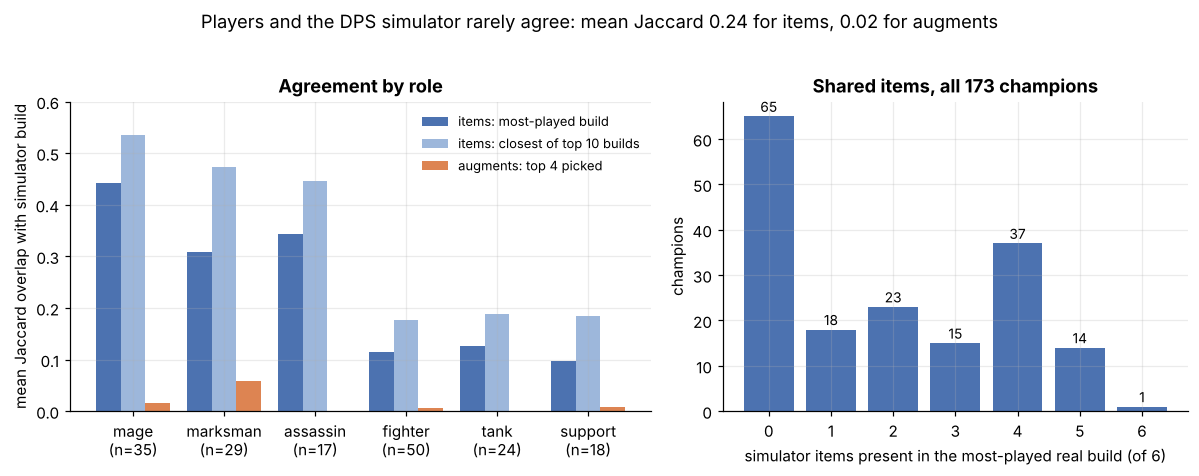

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
x = np.arange(len(ROLE_ORDER)); w = 0.27
ax.bar(x - w, by_role.j_top, w, label='items: most-played build', color='#4C72B0')
ax.bar(x, by_role.j_best10, w, label='items: closest of top 10 builds', color='#9DB7DB')
ax.bar(x + w, by_role.j_aug, w, label='augments: top 4 picked', color='#DD8452')
ax.set_xticks(x); ax.set_xticklabels([f'{r}\n(n={int(by_role.n[r])})' for r in ROLE_ORDER])
ax.set_ylabel('mean Jaccard overlap with simulator build'); ax.set_ylim(0, 0.6)
ax.set_title('Agreement by role'); ax.legend(frameon=False, fontsize=8.5, loc='upper right')
ax = axes[1]
counts = df.shared_top.value_counts().reindex(range(7), fill_value=0)
ax.bar(counts.index, counts.values, color='#4C72B0')
for i, v in counts.items(): ax.text(i, v + 1, str(v), ha='center', fontsize=9)
ax.set_xlabel('simulator items present in the most-played real build (of 6)'); ax.set_ylabel('champions')
ax.set_title('Shared items, all 173 champions')
fig.suptitle('Players and the DPS simulator rarely agree: mean Jaccard %.2f for items, %.2f for augments' % (df.j_top.mean(), df.j_aug.mean()), y=1.02)
fig.tight_layout(); fig.savefig('fig1_agreement_by_role.png', bbox_inches='tight'); plt.show()

## Does closeness to the simulator predict win rate?

**Within champion.** Each champion has ten real builds with a win rate and a pick share. Demeaning
both the win rate and the Jaccard within champion removes everything about the champion itself
and asks only: among the builds this champion's players actually use, do the ones closer to the
simulator win more? Rows are weighted by pick share so that a 0.4%-share build does not count as
much as a 15% one.

**Across champions.** Is the simulator's build closer to the popular build on champions that win
more overall?

In [6]:
bd['wr_dm'] = bd.win_rate - bd.groupby('champion').win_rate.transform('mean')
bd['j_dm'] = bd.jaccard - bd.groupby('champion').jaccard.transform('mean')
w = bd.pick_rate.values
slope_w = np.sum(w * bd.j_dm * bd.wr_dm) / np.sum(w * bd.j_dm ** 2)
slope_u = np.sum(bd.j_dm * bd.wr_dm) / np.sum(bd.j_dm ** 2)
# bootstrap champions for a CI on the weighted slope
rng = np.random.default_rng(0); champs = df.champion.values; boots = []
g = {c: bd[bd.champion == c] for c in champs}
for _ in range(2000):
    s = pd.concat([g[c] for c in rng.choice(champs, len(champs))])
    boots.append(np.sum(s.pick_rate * s.j_dm * s.wr_dm) / np.sum(s.pick_rate * s.j_dm ** 2))
lo, hi = np.percentile(boots, [2.5, 97.5])
print('Within-champion slope of win rate on Jaccard (pick-weighted): %+.2f pp per full unit of Jaccard, 95%% bootstrap CI [%+.2f, %+.2f]; unweighted %+.2f pp' % (100*slope_w, 100*lo, 100*hi, 100*slope_u))
per = bd.groupby('champion').apply(lambda x: stats.spearmanr(x.jaccard, x.win_rate)[0] if x.jaccard.nunique() > 1 else np.nan).dropna()
print('Per-champion Spearman (n=%d champions with any variation): mean %+.3f, %.0f%% positive, Wilcoxon p = %.2f' % (len(per), per.mean(), 100*(per > 0).mean(), stats.wilcoxon(per).pvalue))
by_shared = bd.groupby('shared').apply(lambda x: pd.Series(dict(builds=len(x), mean_pick=x.pick_rate.mean(), wr_vs_champ_mean_pp=100*np.average(x.wr_dm, weights=x.pick_rate))))
print(by_shared.round(2))
print('\nAcross champions: Spearman(top-build Jaccard, baseline win rate) = %+.3f (p = %.3f)' % stats.spearmanr(df.j_top, df.baseline_wr))
print('Across champions, within role (role-demeaned): %+.3f (p = %.3f)' % stats.spearmanr(df.j_top - df.groupby('role').j_top.transform('mean'), df.baseline_wr - df.groupby('role').baseline_wr.transform('mean')))
print('Most-played build win rate minus champion baseline: mean %+.2f pp' % (100*(df.top_wr - df.baseline_wr).mean()))

Within-champion slope of win rate on Jaccard (pick-weighted): +0.62 pp per full unit of Jaccard, 95% bootstrap CI [-1.38, +2.48]; unweighted -0.16 pp
Per-champion Spearman (n=123 champions with any variation): mean +0.038, 52% positive, Wilcoxon p = 0.38
        builds  mean_pick  wr_vs_champ_mean_pp
shared                                        
0        672.0       0.01                -0.04
1        194.0       0.01                -0.48
2        237.0       0.01                -0.07
3        291.0       0.02                 0.13
4        260.0       0.02                 0.10
5         71.0       0.03                 0.17
6          5.0       0.01                 0.97

Across champions: Spearman(top-build Jaccard, baseline win rate) = -0.196 (p = 0.010)
Across champions, within role (role-demeaned): -0.116 (p = 0.129)
Most-played build win rate minus champion baseline: mean +0.05 pp


In [7]:
# sample-size note: Tencent publishes no counts. Using the sibling notebook's lower bound of ~80k games/day
# over the 7 days of patch 16.21 available on 2026-10-28, the median champion appears in 5.4% of games.
games = 80_000 * 7
df['approx_top_build_games'] = games * df.champ_pick * df.top_pick
bd['approx_games'] = bd.champion.map(df.set_index('champion').champ_pick) * bd.pick_rate * games
print('Implied games behind the most-played build (lower bound): median %.0f, IQR %.0f-%.0f; binomial SE at the median ~ %.1f pp' % (
    df.approx_top_build_games.median(), df.approx_top_build_games.quantile(.25), df.approx_top_build_games.quantile(.75), 100*np.sqrt(0.25/df.approx_top_build_games.median())))
print('Tenth-ranked builds: median %.0f games, SE ~ %.1f pp' % (bd[bd.groupby('champion').pick_rate.rank(ascending=False)==10].approx_games.median(), 100*np.sqrt(0.25/bd[bd.groupby('champion').pick_rate.rank(ascending=False)==10].approx_games.median())))

Implied games behind the most-played build (lower bound): median 737, IQR 397-1394; binomial SE at the median ~ 1.8 pp
Tenth-ranked builds: median 209 games, SE ~ 3.5 pp


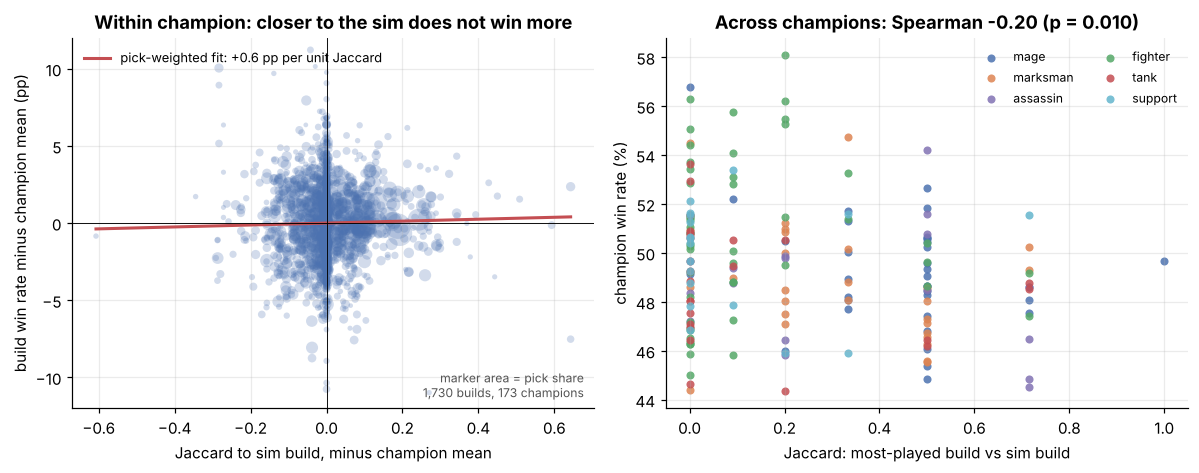

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.scatter(bd.j_dm, 100*bd.wr_dm, s=2000*bd.pick_rate + 4, alpha=0.25, color='#4C72B0', lw=0)
xs = np.linspace(bd.j_dm.min(), bd.j_dm.max(), 10)
ax.plot(xs, 100*slope_w*xs, color='#C44E52', lw=2, label=f'pick-weighted fit: {100*slope_w:+.1f} pp per unit Jaccard')
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('Jaccard to sim build, minus champion mean'); ax.set_ylabel('build win rate minus champion mean (pp)')
ax.set_ylim(-12, 12); ax.set_title('Within champion: closer to the sim does not win more'); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
ax.text(0.98, 0.03, 'marker area = pick share\n1,730 builds, 173 champions', transform=ax.transAxes, ha='right', fontsize=8, color='#555')
ax = axes[1]
for r in ROLE_ORDER:
    s = df[df.role == r]
    ax.scatter(s.j_top, 100*s.baseline_wr, color=ROLE_COL[r], label=r, s=28, alpha=0.85, lw=0)
rho, p = stats.spearmanr(df.j_top, df.baseline_wr)
ax.set_xlabel('Jaccard: most-played build vs sim build'); ax.set_ylabel('champion win rate (%)')
ax.set_title(f'Across champions: Spearman {rho:+.2f} (p = {p:.3f})'); ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig('fig2_agreement_vs_winrate.png', bbox_inches='tight'); plt.show()

## Which items does the simulator over- or under-value?

Item frequency on the simulator side is the share of the 173 champions whose sim-best build
contains the item. On the player side it is the share of champions whose *most-played* build
contains it (the pick-weighted share across all ten builds gives the same picture).

In [9]:
sim_freq, real_freq, real_any = collections.Counter(), collections.Counter(), collections.defaultdict(float)
for c in best:
    cid = key2cid[c['champion']]
    d = json.load(open(P('data', 'cn', 'builds', f'{cid}.json')))
    for s in c['build']['items']: sim_freq[slug2id[s]] += 1
    for i in max(d['items']['full_builds'], key=lambda x: x['pick_rate'])['items']: real_freq[i] += 1
    for x in d['items']['other']: real_any[x['items'][0]] += x['pick_rate']
ids = set(sim_freq) | set(real_freq)
it = pd.DataFrame([dict(id=i, name=id2name.get(i, str(i)), slot=id2slot.get(i, 'not simulated'), sim=sim_freq[i]/len(best), real=real_freq[i]/len(best), real_any_game=real_any[i]/len(best)) for i in ids])
it['diff'] = it.sim - it.real
print('Distinct items: %d in sim builds, %d in top real builds, %d in both; %d of the real items are not in the simulator\'s catalogue' % ((it.sim>0).sum(), (it.real>0).sum(), ((it.sim>0)&(it.real>0)).sum(), ((it.real>0)&(it.slot=='not simulated')).sum()))
print('Spearman(sim frequency, real frequency) over items used by either = %+.2f (p = %.2f)' % stats.spearmanr(it.sim, it.real))
print('\nSimulator OVER-values (sim share - real share of champions):')
print(it.sort_values('diff', ascending=False).head(10)[['name', 'slot', 'sim', 'real', 'diff']].round(3).to_string(index=False))
print('\nSimulator UNDER-values:')
print(it.sort_values('diff').head(10)[['name', 'slot', 'sim', 'real', 'diff']].round(3).to_string(index=False))

Distinct items: 48 in sim builds, 86 in top real builds, 44 in both; 4 of the real items are not in the simulator's catalogue
Spearman(sim frequency, real frequency) over items used by either = +0.22 (p = 0.04)

Simulator OVER-values (sim share - real share of champions):
                    name      slot   sim  real  diff
        Serylda's Grudge legendary 0.318 0.040 0.277
     Berserker's Greaves     boots 0.399 0.139 0.260
               Lich Bane legendary 0.295 0.040 0.254
              Void Staff legendary 0.509 0.283 0.225
        Sorcerer's Shoes     boots 0.526 0.329 0.197
          Nashor's Tooth legendary 0.214 0.029 0.185
              Stormsurge legendary 0.347 0.162 0.185
Blade of The Ruined King legendary 0.301 0.150 0.150
             Shadowflame legendary 0.486 0.347 0.139
           Kraken Slayer legendary 0.145 0.012 0.133

Simulator UNDER-values:
            name          slot   sim  real   diff
Mercury's Treads         boots 0.023 0.254 -0.231
  Warmog's Armor   

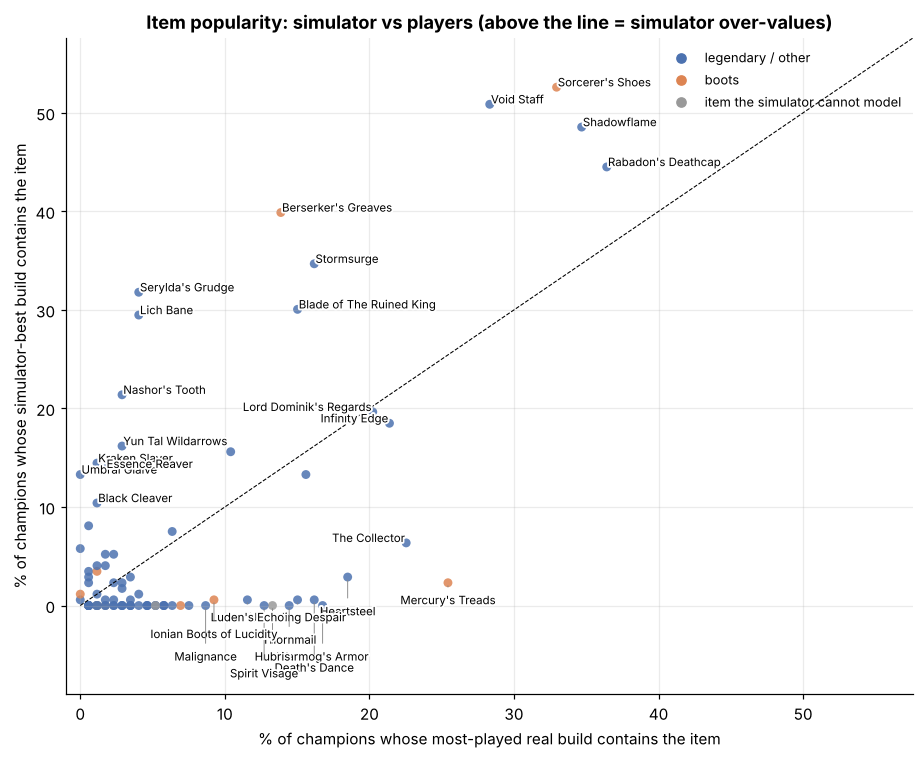

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 7))
col = it.slot.map({'boots': '#DD8452', 'not simulated': '#999999'}).fillna('#4C72B0')
ax.scatter(100*it.real, 100*it.sim, c=col, s=34, alpha=0.85, lw=0)
lim = 100*max(it.sim.max(), it.real.max()) + 5
ax.plot([0, lim], [0, lim], color='k', lw=0.7, ls='--'); ax.set_xlim(-1, lim); ax.set_ylim(-1, lim)
lab = it[(it['diff'].abs() >= 0.08) | (it.sim >= 0.2) | (it.real >= 0.2)]
from matplotlib import patheffects
floor = lab[lab.sim < 0.03].sort_values('real', ascending=False).reset_index(drop=True)
for k, r in floor.iterrows():  # stagger the labels of items the simulator never picks so they do not pile up on the x axis
    ax.annotate(r['name'], (100*r.real, 100*r.sim), xytext=(0, -14 - 11*(k % 4)), textcoords='offset points', fontsize=7.5, ha='center',
                arrowprops=dict(arrowstyle='-', color='#888', lw=0.6), path_effects=[patheffects.withStroke(linewidth=2.5, foreground='white')])
for _, r in lab[lab.sim >= 0.03].iterrows():
    dx = 0.8 if r['diff'] >= 0 else -0.8
    ax.annotate(r['name'], (100*r.real, 100*r.sim), xytext=(dx, 0.6), textcoords='offset points', fontsize=7.5, ha='left' if dx > 0 else 'right',
                path_effects=[patheffects.withStroke(linewidth=2.5, foreground='white')])
ax.set_ylim(-9, lim)
ax.set_xlabel('% of champions whose most-played real build contains the item'); ax.set_ylabel('% of champions whose simulator-best build contains the item')
ax.set_title('Item popularity: simulator vs players (above the line = simulator over-values)')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', color='#4C72B0', label='legendary / other'), Line2D([], [], marker='o', ls='', color='#DD8452', label='boots'),
                   Line2D([], [], marker='o', ls='', color='#999999', label='item the simulator cannot model')], frameon=False, fontsize=8.5, loc='upper right')
fig.tight_layout(); fig.savefig('fig3_item_sim_vs_real.png', bbox_inches='tight'); plt.show()

## Augments

In [11]:
sim_aug_freq = collections.Counter(aid2name[aslug2id[s]] for c in best for s in c['build']['augments'])
real_top4 = collections.Counter()
for c in best:
    d = json.load(open(P('data', 'cn', 'builds', f"{key2cid[c['champion']]}.json")))
    for x in sorted(d['augments']['all'], key=lambda x: -x['pick_rate'])[:4]:
        real_top4[aid2name.get(x['id'], cn_augs.get(x['id'], {}).get('key', str(x['id'])))] += 1
at = pd.DataFrame({'sim_builds': pd.Series(sim_aug_freq), 'real_top4': pd.Series(real_top4)}).fillna(0).astype(int)
name2aid = {v: k for k, v in aid2name.items()}
at['server_pick_rate'] = [cn_augs.get(name2aid.get(k, -1), {}).get('pick_rate', np.nan) for k in at.index]
print('Simulator\'s favourite augments (count of 173 builds) vs how often they are a champion\'s top-4 pick:')
print(at.sort_values('sim_builds', ascending=False).head(10).to_string())
print('\nPlayers\' favourite augments (server-wide pick rate is Tencent\'s share of games containing the augment):')
print(at.sort_values('real_top4', ascending=False).head(10).to_string())

Simulator's favourite augments (count of 173 builds) vs how often they are a champion's top-4 pick:
                      sim_builds  real_top4  server_pick_rate
Giant Slayer                 135          0            0.2888
Forged By The Master          73          0               NaN
Glass Cannon                  59          0            0.0494
En Passant                    48          0            0.0831
Dive Bomber                   46          0            0.2359
Dual Wield                    45         12            0.2663
Back To Basics                42          4            0.3123
Marksmage                     25         10            0.1905
Symphony of War               25          0            0.1359
Scopiest Weapons              17          0            0.2105

Players' favourite augments (server-wide pick rate is Tencent's share of games containing the augment):
                       sim_builds  real_top4  server_pick_rate
BEES!!!                         0         60      

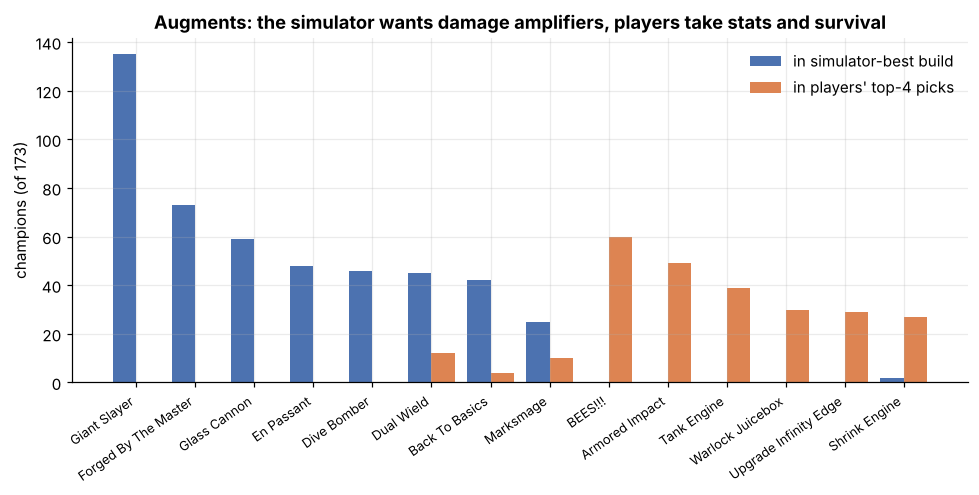

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
top = at.sort_values('sim_builds', ascending=False).head(8).index.tolist() + [a for a in at.sort_values('real_top4', ascending=False).head(8).index if a not in at.sort_values('sim_builds', ascending=False).head(8).index][:6]
sub = at.loc[top]
x = np.arange(len(sub)); w = 0.4
ax.bar(x - w/2, sub.sim_builds, w, color='#4C72B0', label='in simulator-best build')
ax.bar(x + w/2, sub.real_top4, w, color='#DD8452', label="in players' top-4 picks")
ax.set_xticks(x); ax.set_xticklabels(sub.index, rotation=35, ha='right', fontsize=8.5)
ax.set_ylabel('champions (of 173)'); ax.legend(frameon=False)
ax.set_title('Augments: the simulator wants damage amplifiers, players take stats and survival')
fig.tight_layout(); fig.savefig('fig4_augments.png', bbox_inches='tight'); plt.show()

In [13]:
df.sort_values('j_top', ascending=False)[['champion', 'role', 'j_top', 'j_best10', 'shared_top', 'j_aug', 'baseline_wr', 'top_wr', 'top_pick']].round(3).head(15)

,champion,role,j_top,j_best10,shared_top,j_aug,baseline_wr,top_wr,top_pick
79,Sylas,mage,1.000,1.000,6,0.000,0.497,0.498,0.009
35,Yunara,marksman,0.714,0.714,5,0.143,0.493,0.482,0.030
26,Caitlyn,marksman,0.714,1.000,5,0.000,0.502,0.473,0.035
19,Leblanc,assassin,0.714,0.714,5,0.000,0.445,0.458,0.137
4,Azir,mage,0.714,0.714,5,0.143,0.481,0.488,0.029
131,Locke,assassin,0.714,0.714,5,0.000,0.465,0.483,0.102
153,Evelynn,assassin,0.714,0.714,5,0.000,0.486,0.526,0.159
107,Diana,fighter,0.714,1.000,5,0.000,0.474,0.442,0.030
83,Gragas,fighter,0.714,0.714,5,0.000,0.492,0.476,0.047
80,Akali,assassin,0.714,1.000,5,0.000,0.448,0.458,0.037
